# Polynomial Regression

A straight line cannot follow a curve. Polynomial regression adds columns for x², x³ and so on, then runs the same linear regression on all of them. Here it predicts **mpg** from **horsepower**, which curves.

This notebook goes with the **Polynomial Regression** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split → add the power columns → fit → compare degrees → draw the curve.

## 1. Load the data

Each row is a car from the late 1970s and early 1980s. We predict `mpg` from `horsepower`. A few cars have no horsepower listed, so we drop them first.

The data is the [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) data set from the UCI Machine Learning Repository (CC BY 4.0). See `datasets/README.md` for what we changed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/mpg.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,usa
1,15.0,8,350.0,165.0,3693,11.5,70,usa
2,18.0,8,318.0,150.0,3436,11.0,70,usa
3,16.0,8,304.0,150.0,3433,12.0,70,usa
4,17.0,8,302.0,140.0,3449,10.5,70,usa


In [2]:
dataset = dataset.dropna(subset=['horsepower'])
X = dataset[['horsepower']].values
y = dataset['mpg'].values
print(X.shape, 'cars')

(392, 1) cars


## 2. Split into train and test

The model learns from the **training** cars (75%). We hold back the other 25% and only use them at the end. The test score shows how the model does on cars it has never seen. These are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

294 train, 98 test


## 3. Scale, then add the power columns and fit

Horsepower is in the hundreds, so its 8th power is astronomically large and the fit becomes unstable. We **scale x first** (fit on the training cars only), then build the powers.

`PolynomialFeatures(degree=2)` turns each x into the columns 1, x, x². The regression on top of it is still linear in the weights.

In [4]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

poly = PolynomialFeatures(degree=2)
X_poly_train = poly.fit_transform(X_train_s)
regressor = LinearRegression()
regressor.fit(X_poly_train, y_train)
print('columns:', poly.get_feature_names_out())
print('weights:', regressor.coef_.round(4))

columns: ['1' 'x0' 'x0^2']
weights: [ 0.     -7.8548  1.702 ]


## 4. Check the result

**R²** says how much of the ups and downs in the data the model explains. 1 is perfect, 0 is no better than always guessing the average. The number that matters is the **test** R². The last line shows the typical miss in miles per gallon.

In [5]:
y_pred_train = regressor.predict(poly.transform(X_train_s))
y_pred_test = regressor.predict(poly.transform(X_test_s))
print('Train R²:', round(r2_score(y_train, y_pred_train), 3))
print('Test R²: ', round(r2_score(y_test, y_pred_test), 3))
print('Test error on average:', round(mean_absolute_error(y_test, y_pred_test), 2), 'mpg')

Train R²: 0.674
Test R²:  0.727
Test error on average: 2.97 mpg


## 5. Choose the degree

Too low and the curve misses the pattern. Too high and it bends to follow noise. Compare train and test R² for each degree. Raise the degree only while the **test** score keeps rising.

In [6]:
for degree in range(1, 9):
    p = PolynomialFeatures(degree=degree)
    m = LinearRegression().fit(p.fit_transform(X_train_s), y_train)
    tr = r2_score(y_train, m.predict(p.transform(X_train_s)))
    te = r2_score(y_test, m.predict(p.transform(X_test_s)))
    print(f'degree {degree}: train R² {tr:.3f}   test R² {te:.3f}')

degree 1: train R² 0.600   test R² 0.622
degree 2: train R² 0.674   test R² 0.727
degree 3: train R² 0.675   test R² 0.728
degree 4: train R² 0.676   test R² 0.730
degree 5: train R² 0.685   test R² 0.732
degree 6: train R² 0.688   test R² 0.735
degree 7: train R² 0.691   test R² 0.736
degree 8: train R² 0.692   test R² 0.734


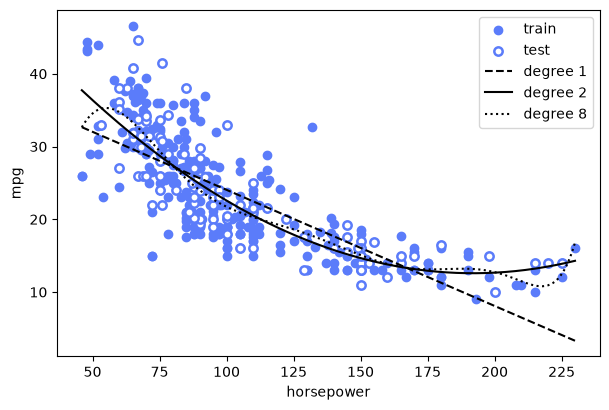

In [7]:
grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_train, y_train, color='#5b7cfa', label='train')
plt.scatter(X_test, y_test, facecolors='white', edgecolors='#5b7cfa', linewidths=1.8, label='test')
for degree, style in [(1, '--'), (2, '-'), (8, ':')]:
    p = PolynomialFeatures(degree=degree)
    m = LinearRegression().fit(p.fit_transform(X_train_s), y_train)
    plt.plot(grid, m.predict(p.transform(sc.transform(grid))), style, color='black', label=f'degree {degree}')
plt.xlabel('horsepower'); plt.ylabel('mpg'); plt.legend()
plt.show()

## Try this

1. Which degree has the best test R²? Does it change if you change `random_state`?
2. Look at the degree 8 curve at the right-hand end, where there are few cars. What does it do?
3. Predict the mpg of a 130 hp car with your best degree.

## See it: the fit and the misses

**Left:** the fitted curve through the cars. Filled dots are training cars and ringed dots are test cars. The test R² is in the title. **Right:** the residuals, which are the misses (actual mpg minus predicted mpg). **Notice how** the curve bends with the cars, but the residuals still spread out as the predicted mpg rises: cars with a high mpg are harder to predict from horsepower alone.

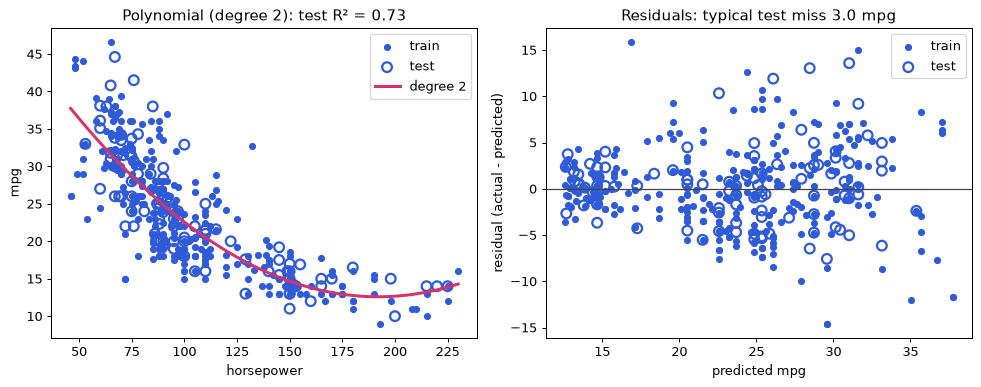

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

def model_predict(X_raw):
    return regressor.predict(poly.transform(sc.transform(X_raw)))

xs = X[:, :1]
fit_x = np.linspace(xs.min(), xs.max(), 300).reshape(-1, 1)
yt, yte = np.ravel(y_train), np.ravel(y_test)
p_tr, p_te = model_predict(X_train), model_predict(X_test)
r2 = r2_score(yte, p_te)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.scatter(X_train[:, 0], yt, color=BLUE, s=22, label='train')
ax1.scatter(X_test[:, 0], yte, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax1.plot(fit_x[:, 0], model_predict(fit_x), color=PINK, linewidth=2.4, label='degree 2')
ax1.set_xlabel('horsepower'); ax1.set_ylabel('mpg')
ax1.set_title(f'Polynomial (degree 2): test R² = {r2:.2f}')
ax1.legend()

ax2.axhline(0, color='#444444', linewidth=1)
ax2.scatter(p_tr, yt - p_tr, color=BLUE, s=22, label='train')
ax2.scatter(p_te, yte - p_te, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax2.set_xlabel('predicted mpg'); ax2.set_ylabel('residual (actual - predicted)')
ax2.set_title(f'Residuals: typical test miss {np.abs(yte - p_te).mean():.1f} mpg')
ax2.legend()
fig.tight_layout()
plt.show()
